In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e11/train.csv
/kaggle/input/competitions/playground-series-s6e11/test.csv


In [2]:
train = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/train.csv')
test = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/test.csv')

train.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [3]:
train.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191548,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [4]:
train.dtypes

id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                object
card_type                        object
auth_method                      object
channel                          object
device_type                      object
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-nul

In [6]:
train.isnull().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

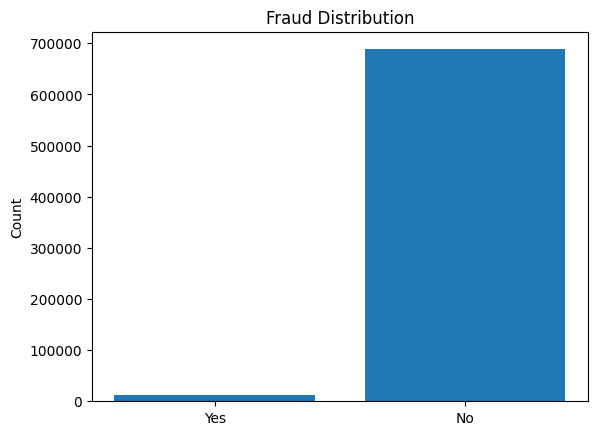

In [8]:
plt.bar(['Yes', 'No'], [(train['is_fraud'] == 1).sum(), (train['is_fraud']  == 0).sum()])
plt.ylabel('Count')
plt.title('Fraud Distribution')
plt.show()

In [9]:
print(train['is_fraud'].value_counts())
print("="*100)
round((train['is_fraud'].value_counts()[1]/train['is_fraud'].count())*100 , 2)

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64


np.float64(1.67)

<Axes: xlabel='amount_usd', ylabel='hours_since_last_txn'>

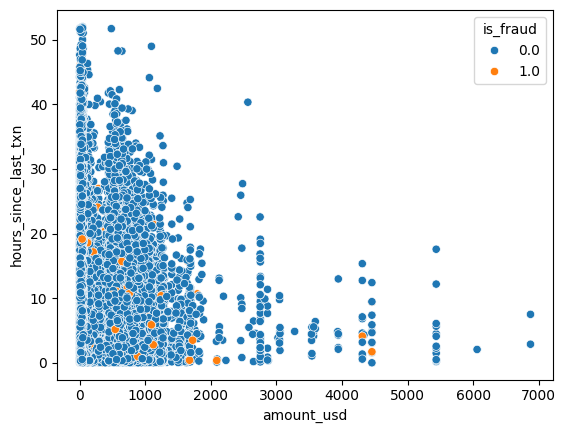

In [10]:
sns.scatterplot(data=train[:200000], x="amount_usd", y="hours_since_last_txn",hue = 'is_fraud')

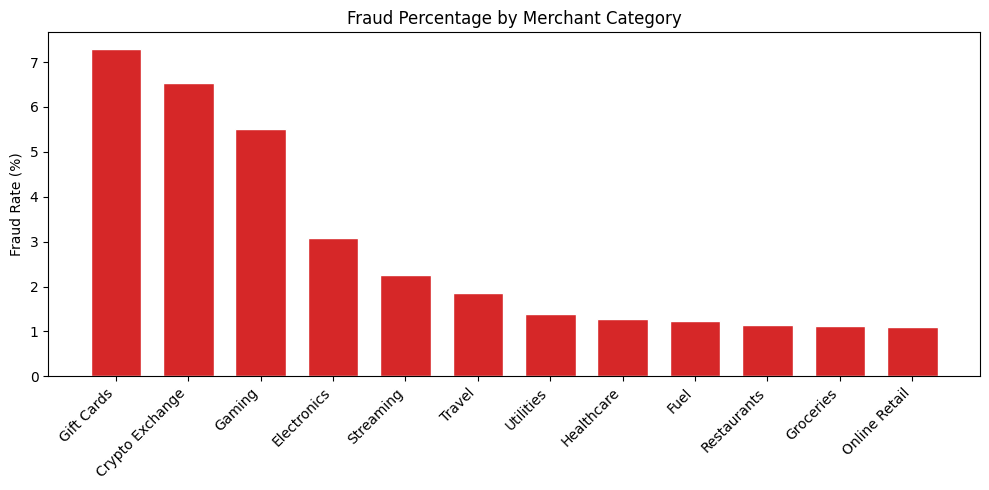

In [11]:
fraud_rate = train.groupby('merchant_category')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by Merchant Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

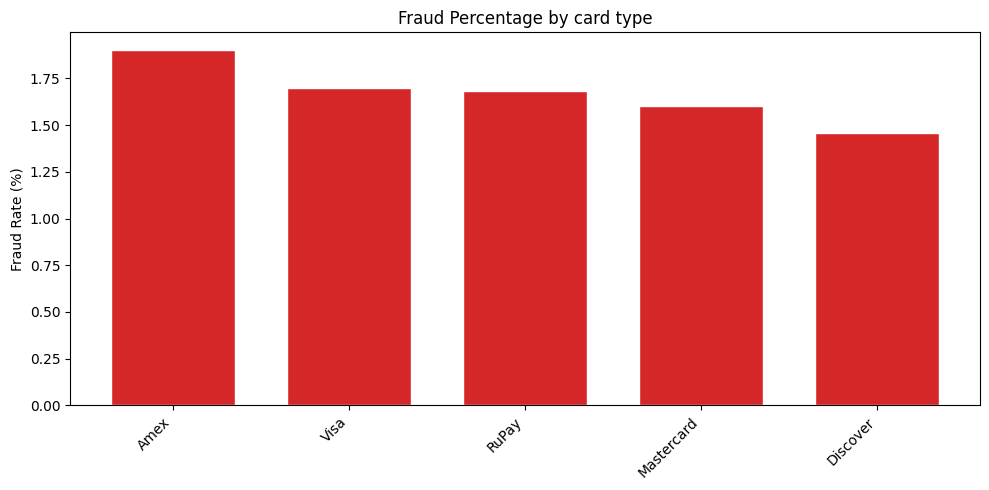

In [12]:
fraud_rate = train.groupby('card_type')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by card type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

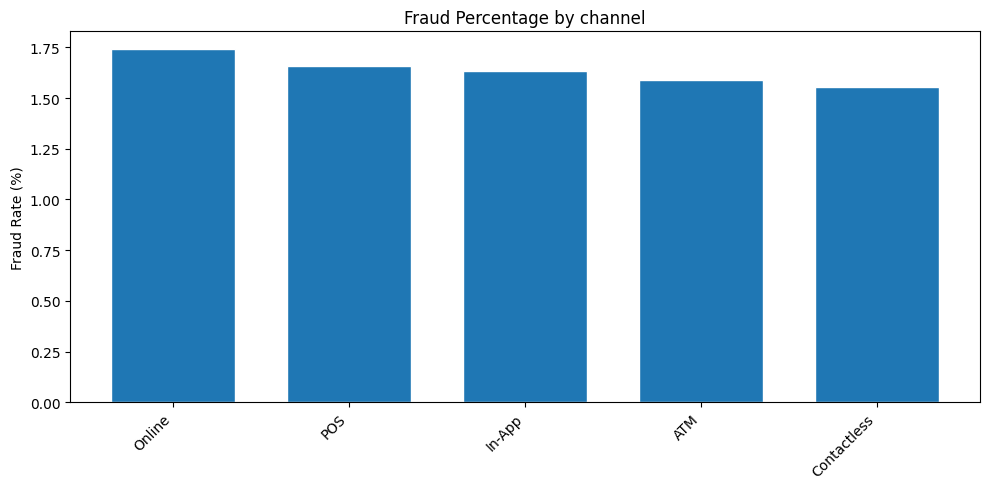

In [13]:
fraud_rate = train.groupby('channel')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:blue", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by channel")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

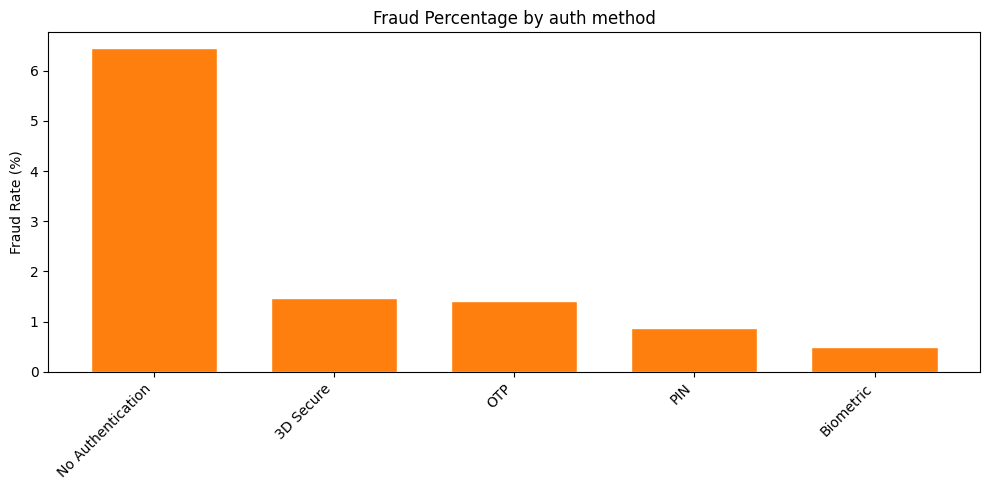

In [14]:
fraud_rate = train.groupby('auth_method')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:orange", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by auth method")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

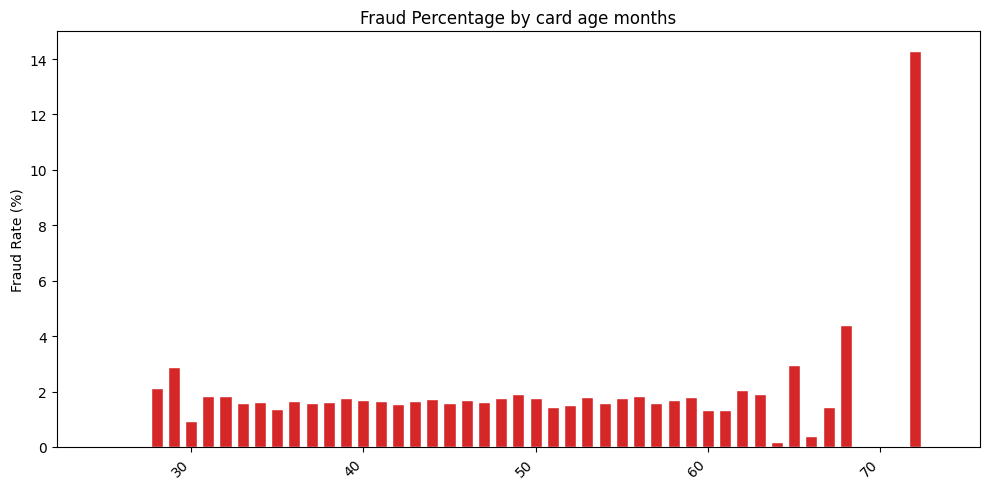

In [15]:
fraud_rate = train.groupby('card_age_months')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by card age months")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

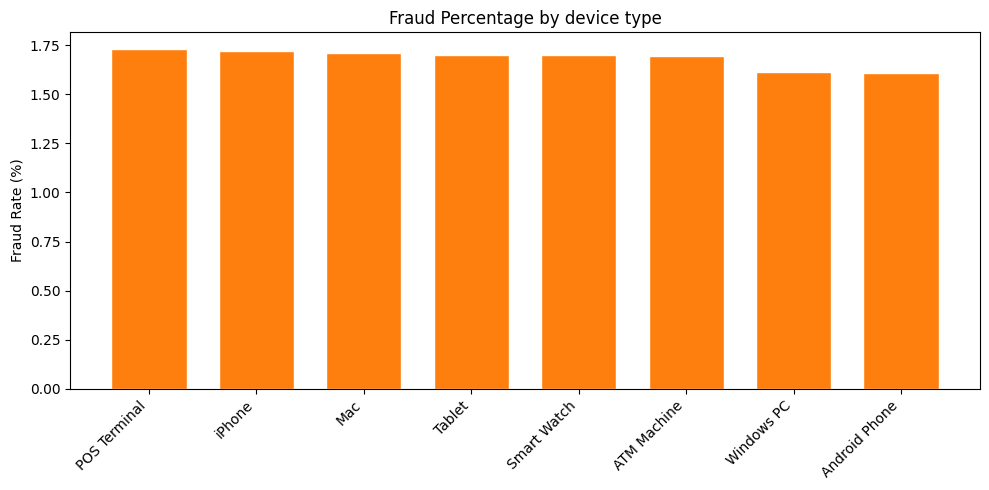

In [16]:
fraud_rate = train.groupby('device_type')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:orange", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by device type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

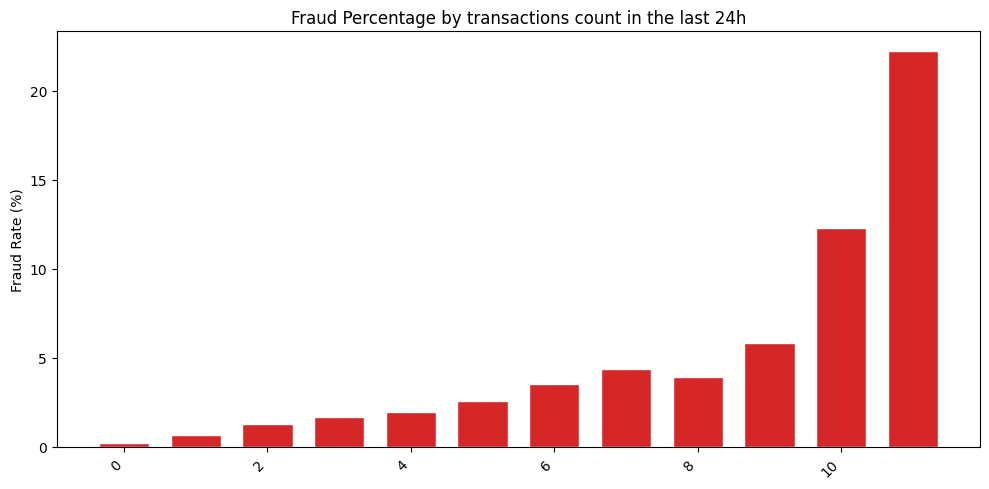

In [17]:
fraud_rate = train.groupby('txn_count_last_24h')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by transactions count in the last 24h")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

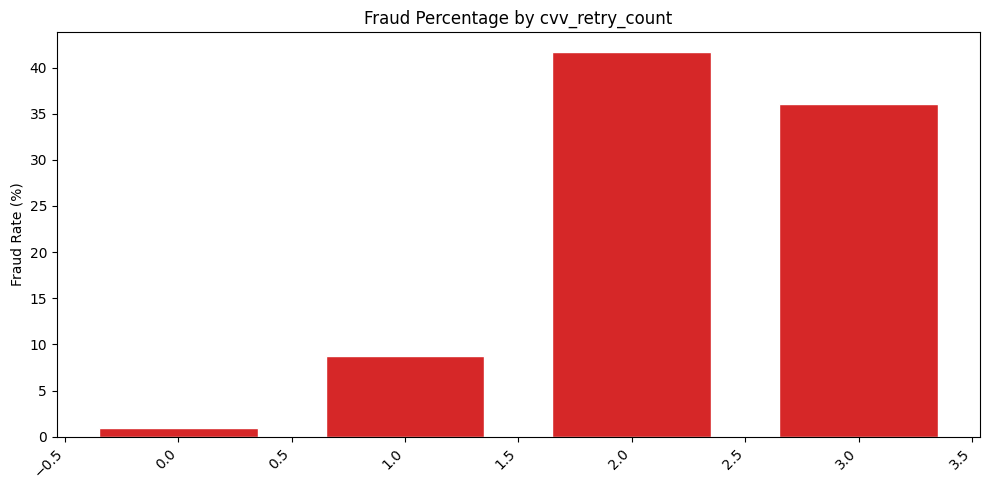

In [18]:
fraud_rate = train.groupby('cvv_retry_count')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by cvv_retry_count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

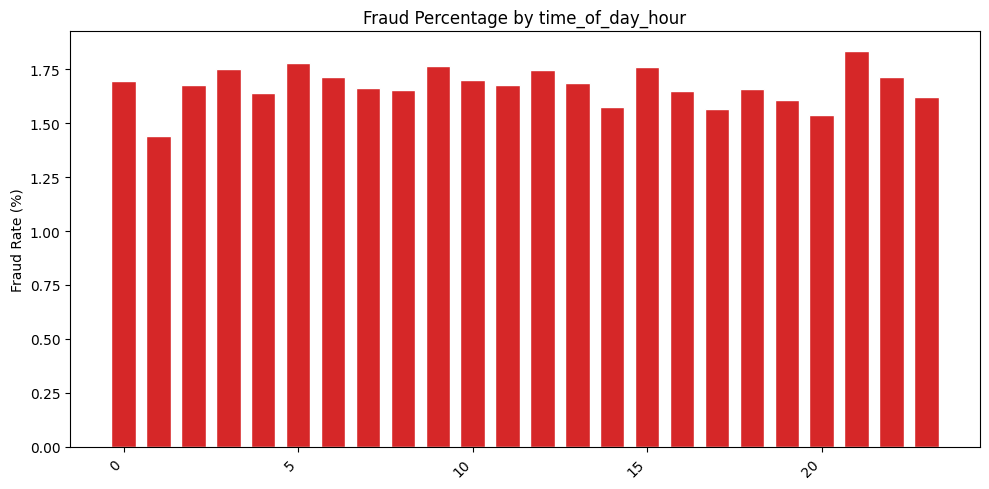

In [19]:
fraud_rate = train.groupby('time_of_day_hour')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by time_of_day_hour")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

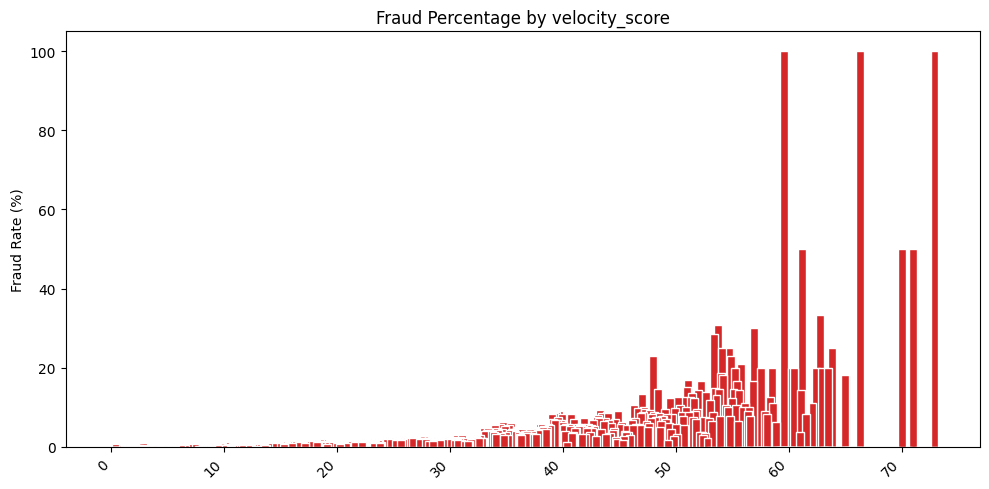

In [20]:
fraud_rate = train.groupby('velocity_score')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by velocity_score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

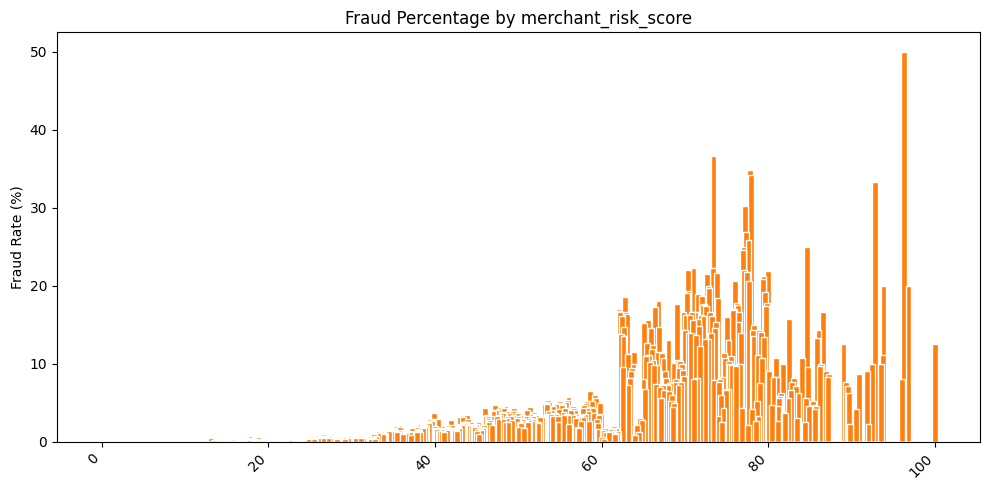

In [21]:
fraud_rate = train.groupby('merchant_risk_score')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:orange", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by merchant_risk_score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

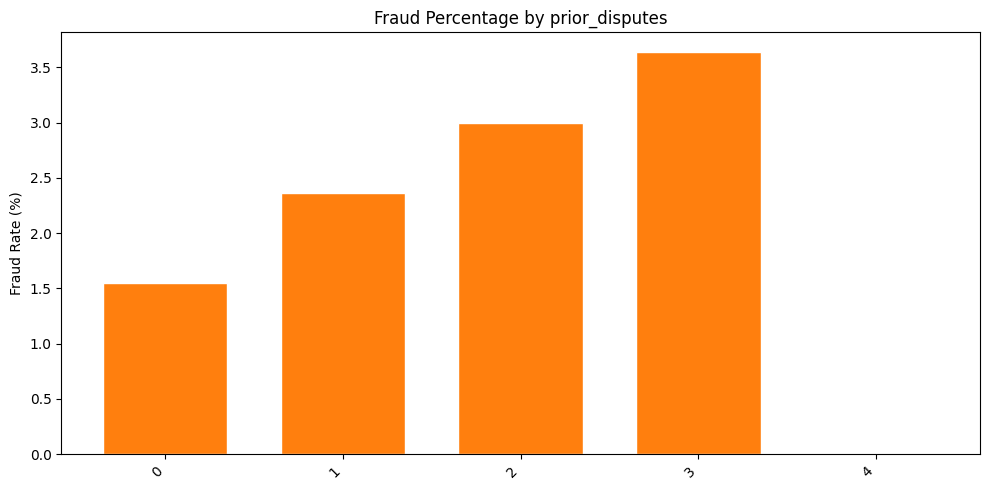

In [22]:
fraud_rate = train.groupby('prior_disputes')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:orange", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by prior_disputes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

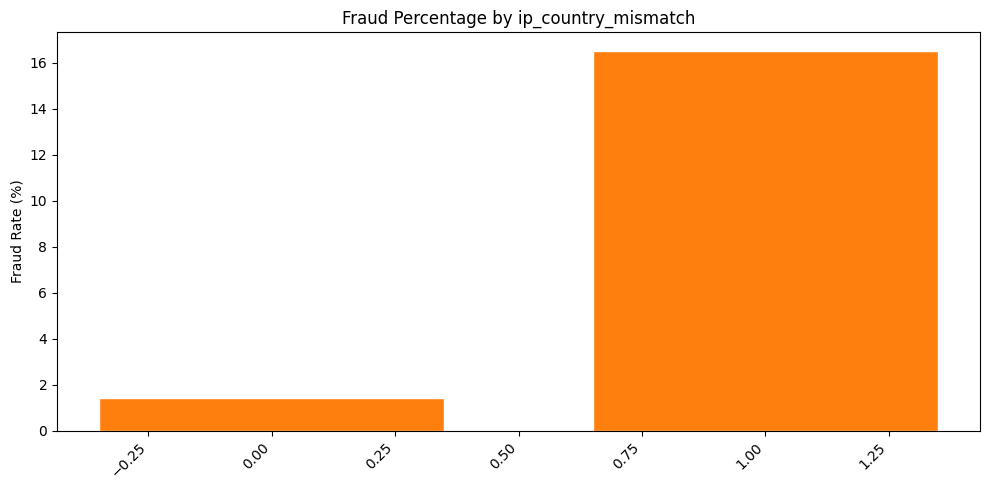

In [23]:
fraud_rate = train.groupby('ip_country_mismatch')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:orange", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by ip_country_mismatch")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

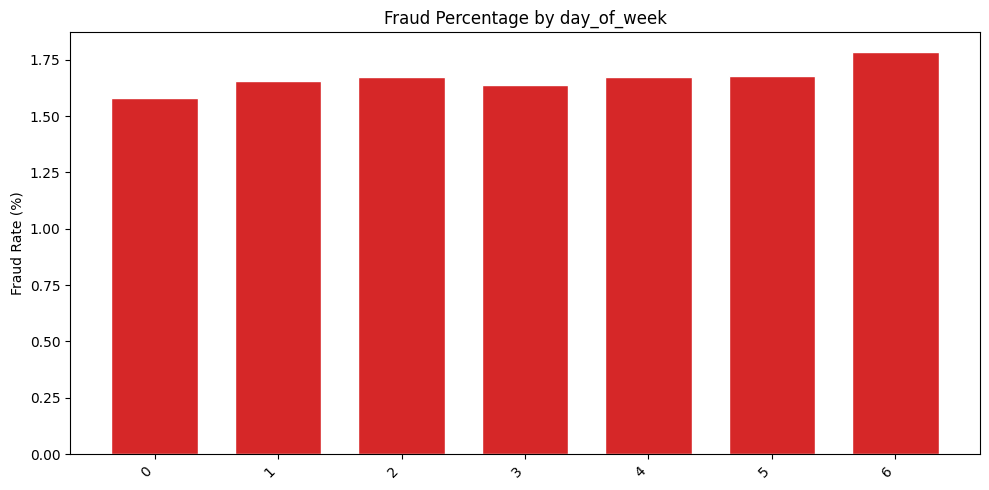

In [24]:
fraud_rate = train.groupby('day_of_week')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by day_of_week")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

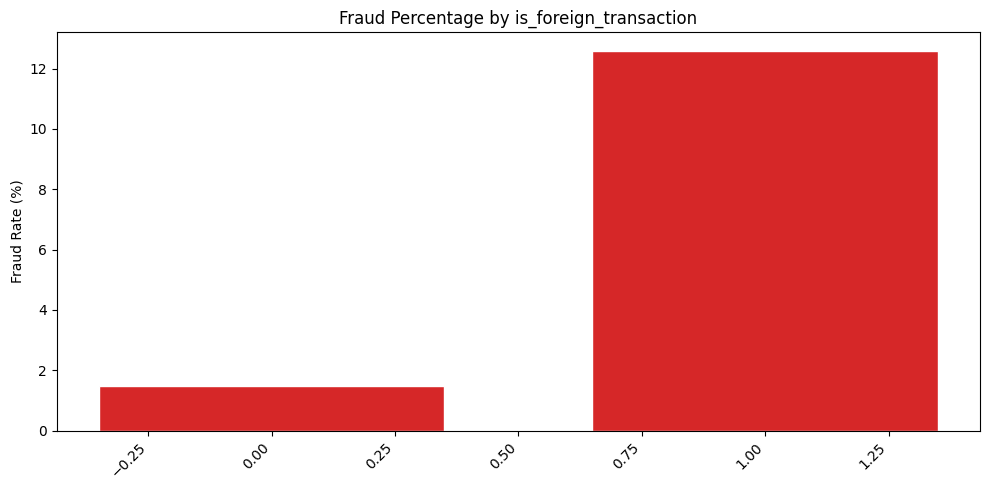

In [25]:
fraud_rate = train.groupby('is_foreign_transaction')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:red", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by is_foreign_transaction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

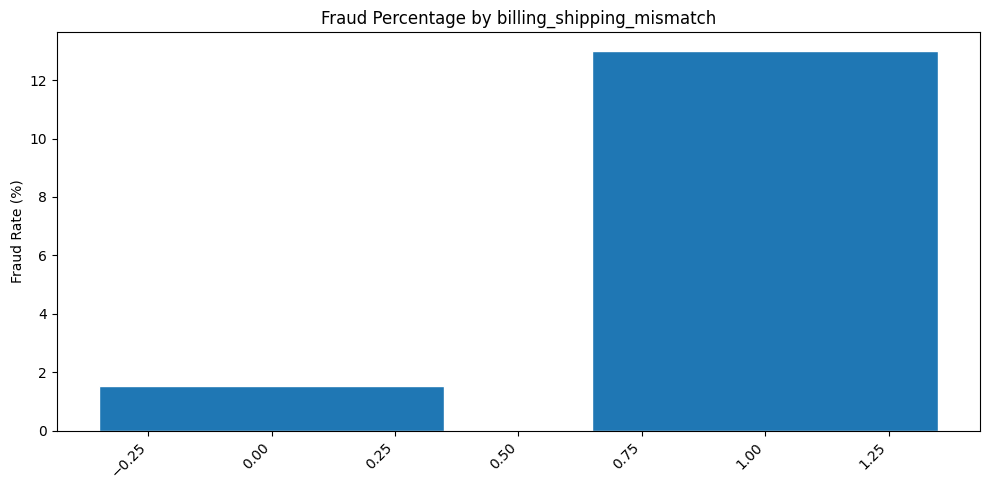

In [26]:
fraud_rate = train.groupby('billing_shipping_mismatch')['is_fraud'].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fraud_rate.index, fraud_rate.values, color="tab:blue", width=0.7, edgecolor="white")

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Percentage by billing_shipping_mismatch")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [27]:
def preprocess(df):
    df = df.copy()
    
    # 1. Financial ratios (keep raw columns too)
    df['amount_percentage'] = df['amount_usd'] / (df['account_balance_usd'] + 1e-5)
    df['balance_remaining'] = df['account_balance_usd'] - df['amount_usd']
    
    # 2. Behavioral & impossible-travel features
    df['travel_speed_kmh'] = df['distance_from_home_km'] / (df['hours_since_last_txn'] + 0.1)
    df['is_late_night'] = df['time_of_day_hour'].between(0, 5).astype(int)
    
    # 3. Convert booleans to int & sum risk flags
    bool_cols = [
        'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
        'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt'
    ]
    df[bool_cols] = df[bool_cols].astype(int)
    df['total_risk_flags'] = df[bool_cols].sum(axis=1)
    
    # 4. Categorical encoding (for LightGBM/XGBoost)
    cat_cols = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
    for col in cat_cols:
        df[col] = df[col].astype('category')
        
    return df

train_fe = preprocess(train)
test_fe = preprocess(test)

features = [c for c in train_fe.columns if c not in ['id', 'is_fraud']]
X = train_fe[features]
Y = train_fe['is_fraud']
X_test = test_fe[features]

In [28]:
'''from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_train, X_val, y_train, y_val = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

model_test = make_pipeline(StandardScaler(),
                    SGDClassifier(max_iter=1000, tol=1e-3))

model_test.fit(X_train, y_train)


val_preds = model_test.predict(X_val)
print(classification_report(y_val, val_preds))'''

'from sklearn.model_selection import train_test_split\nfrom sklearn.linear_model import SGDClassifier\nfrom sklearn.metrics import roc_auc_score, classification_report\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.pipeline import make_pipeline\n\nX_train, X_val, y_train, y_val = train_test_split(\n    X, Y, test_size=0.2, random_state=42, stratify=Y\n)\n\nmodel_test = make_pipeline(StandardScaler(),\n                    SGDClassifier(max_iter=1000, tol=1e-3))\n\nmodel_test.fit(X_train, y_train)\n\n\nval_preds = model_test.predict(X_val)\nprint(classification_report(y_val, val_preds))'

In [29]:
'''model = make_pipeline(StandardScaler(),
                    SGDClassifier(max_iter=1000, tol=1e-3))

model.fit(X, Y)'''


'model = make_pipeline(StandardScaler(),\n                    SGDClassifier(max_iter=1000, tol=1e-3))\n\nmodel.fit(X, Y)'

In [30]:
'''from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=1)
model_dt.fit(X, Y)'''

'from sklearn.tree import DecisionTreeClassifier\n\nmodel_dt = DecisionTreeClassifier(random_state=1)\nmodel_dt.fit(X, Y)'

In [31]:
'''from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model_LR = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=500, random_state=0)
)
model_LR.fit(X, Y)'''

'from sklearn.linear_model import LogisticRegression\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.pipeline import make_pipeline\n\nmodel_LR = make_pipeline(\n    StandardScaler(),\n    LogisticRegression(max_iter=500, random_state=0)\n)\nmodel_LR.fit(X, Y)'

In [32]:
'''from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedBaggingClassifier


base_classifier = RandomForestClassifier(random_state=42)

model_RFC = make_pipeline(
    StandardScaler(),
    BalancedBaggingClassifier(
            estimator=base_classifier,
            sampling_strategy='auto',
            replacement=False,
            random_state=42
        )
)
model_RFC.fit(X, Y)
'''

"from sklearn.ensemble import RandomForestClassifier\nfrom imblearn.ensemble import BalancedBaggingClassifier\n\n\nbase_classifier = RandomForestClassifier(random_state=42)\n\nmodel_RFC = make_pipeline(\n    StandardScaler(),\n    BalancedBaggingClassifier(\n            estimator=base_classifier,\n            sampling_strategy='auto',\n            replacement=False,\n            random_state=42\n        )\n)\nmodel_RFC.fit(X, Y)\n"

In [33]:
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'max_depth': 6,
    'learning_rate': 0.05,
    'n_estimators': 1000,
    'reg_alpha': 10,
    'enable_categorical': True,  
    'n_jobs': -1,
    'random_state': 42
}
model_XGBC = XGBClassifier(**params)

model_XGBC.fit(X, Y)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=-1, num_parallel_tree=None, ...)

In [34]:
X_test_aligned = X_test[X.columns]

test_preds = model_XGBC.predict_proba(X_test_aligned)[:, 1]
#.predict(X_test_aligned)

submission = pd.DataFrame({
    'id': test['id'],
    'is_fraud': test_preds
})

submission.to_csv('submission.csv', index=False)
print(submission.head())

       id  is_fraud
0  699960  0.000161
1  699961  0.000057
2  699962  0.044444
3  699963  0.001437
4  699964  0.000664
